# Задание 3. Военный или гражданский самолёт?

По фотографии определить, к какой авиации относится самолёт — военной или гражданской.

По условиям задания надо использовать LLM и **сравнить метрики двух моделей**. Вместо облачных провайдеров Hugging Face берём две **локальные** модели со «зрением» (VLM), запускаем их на локальном GPU NVIDIA H100 и отправляем им фотографии через OpenAI-совместимый API (vLLM):

| модель | размер | роль |
|---|---|---|
| Qwen3.8-27B | 27 млрд параметров | «сильная» |
| Phi-3.5-Vision | ~4 млрд параметров | «слабая» |

План: датасет → один и тот же промпт для обоих → ответы → метрики (accuracy, precision/recall/F1, матрица ошибок) → разбор нетривиальных случаев.


In [1]:
import base64
import csv
import json
import os
import re
import time

import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
from PIL import Image as PILImage

print("импорты OK: pandas", pd.__version__, "| requests", requests.__version__)

импорты OK: pandas 3.0.5 | requests 2.34.2


## 1. Данные: 34 фото, 17 + 17

Самолёты лежат в папке `aircraft/` рядом с этим ноутбуком, разметка — `aircraft/labels_pre.csv` (utf-8, разделитель `;`): кто на фото, почему так подписано, и насколько фото «хитрое» (`difficulty`: easy / medium / hard).

Выборка намеренно **не чистая** — в ней нетривиальные случаи:
- «военно выглядящие» гражданские: Ан-12 в гражданской ливрее, Ан-124 «Руслан», Ан-2 «кукурузник»;
- госпрограммы, подписанные как гражданские: шаттл «Буран», грузовой NASA Wonderrunner;
- пожарный самолёт, летающая машина PAL-V, сверхлёгкий двухместный;
- дальний борт без знаков, винтажные ч/б фото, биплан Первой мировой.

Именно на них видно, как модели рассуждают.


In [2]:
def find_dataset():
    """Папка aircraft/ — от текущего каталога и от корня репозитория."""
    here = os.getcwd()
    for c in (os.path.join(here, "aircraft"),
              os.path.join(here, "..", "aircraft"),
              os.path.join(here, "..", "..", "aircraft")):
        if os.path.exists(os.path.join(c, "labels_pre.csv")):
            return os.path.abspath(c)
    raise FileNotFoundError("не найдена папка aircraft/ с labels_pre.csv")


DATASET_DIR = find_dataset()
CSV_PATH = os.path.join(DATASET_DIR, "labels_pre.csv")
print("Датасет:", DATASET_DIR)

records = []
with open(CSV_PATH, encoding="utf-8-sig", newline="") as f:
    for r in csv.DictReader(f, delimiter=";"):
        label = (r.get("my_label") or "").strip().lower()
        if label not in ("military", "civilian"):
            continue
        records.append({
            "file": r["file"].strip(),
            "gt": "ВОЕННЫЙ" if label == "military" else "ГРАЖДАНСКИЙ",
            "difficulty": (r.get("difficulty") or "").strip(),
            "reason": (r.get("my_reason") or "").strip(),
        })

df = pd.DataFrame(records)
assert len(df) == 34, f"ожидалось 34 фото, а в CSV {len(df)}"
assert (df["gt"] == "ВОЕННЫЙ").sum() == 17 and (df["gt"] == "ГРАЖДАНСКИЙ").sum() == 17

print("всего фото:", len(df),
      "| военных:", (df["gt"] == "ВОЕННЫЙ").sum(),
      "| гражданских:", (df["gt"] == "ГРАЖДАНСКИЙ").sum(),
      "| hard:", (df["difficulty"] == "hard").sum())
df[["file", "gt", "difficulty"]].to_string(index=False)

Датасет: /home/ipetrichenko/mirea-ai/notebooks/03_aircraft_llm/aircraft
всего фото: 34 | военных: 17 | гражданских: 17 | hard: 12


'               file          gt difficulty\nmilitary/mil_01.jpg     ВОЕННЫЙ       easy\nmilitary/mil_02.jpg     ВОЕННЫЙ       easy\nmilitary/mil_03.jpg     ВОЕННЫЙ       hard\nmilitary/mil_04.jpg     ВОЕННЫЙ     medium\nmilitary/mil_05.jpg     ВОЕННЫЙ       hard\nmilitary/mil_06.jpg     ВОЕННЫЙ       easy\nmilitary/mil_07.jpg     ВОЕННЫЙ     medium\nmilitary/mil_08.jpg     ВОЕННЫЙ       easy\nmilitary/mil_09.jpg     ВОЕННЫЙ       easy\nmilitary/mil_10.jpg     ВОЕННЫЙ     medium\nmilitary/mil_11.jpg     ВОЕННЫЙ       easy\nmilitary/mil_12.jpg     ВОЕННЫЙ     medium\nmilitary/mil_13.jpg     ВОЕННЫЙ     medium\nmilitary/mil_14.jpg     ВОЕННЫЙ       easy\nmilitary/mil_15.jpg     ВОЕННЫЙ       easy\nmilitary/mil_16.jpg     ВОЕННЫЙ     medium\nmilitary/mil_17.jpg     ВОЕННЫЙ     medium\ncivilian/civ_01.jpg ГРАЖДАНСКИЙ       hard\ncivilian/civ_02.jpg ГРАЖДАНСКИЙ       easy\ncivilian/civ_03.jpg ГРАЖДАНСКИЙ       easy\ncivilian/civ_04.jpg ГРАЖДАНСКИЙ       hard\ncivilian/civ_05.jpg ГРАЖДАНСКИЙ

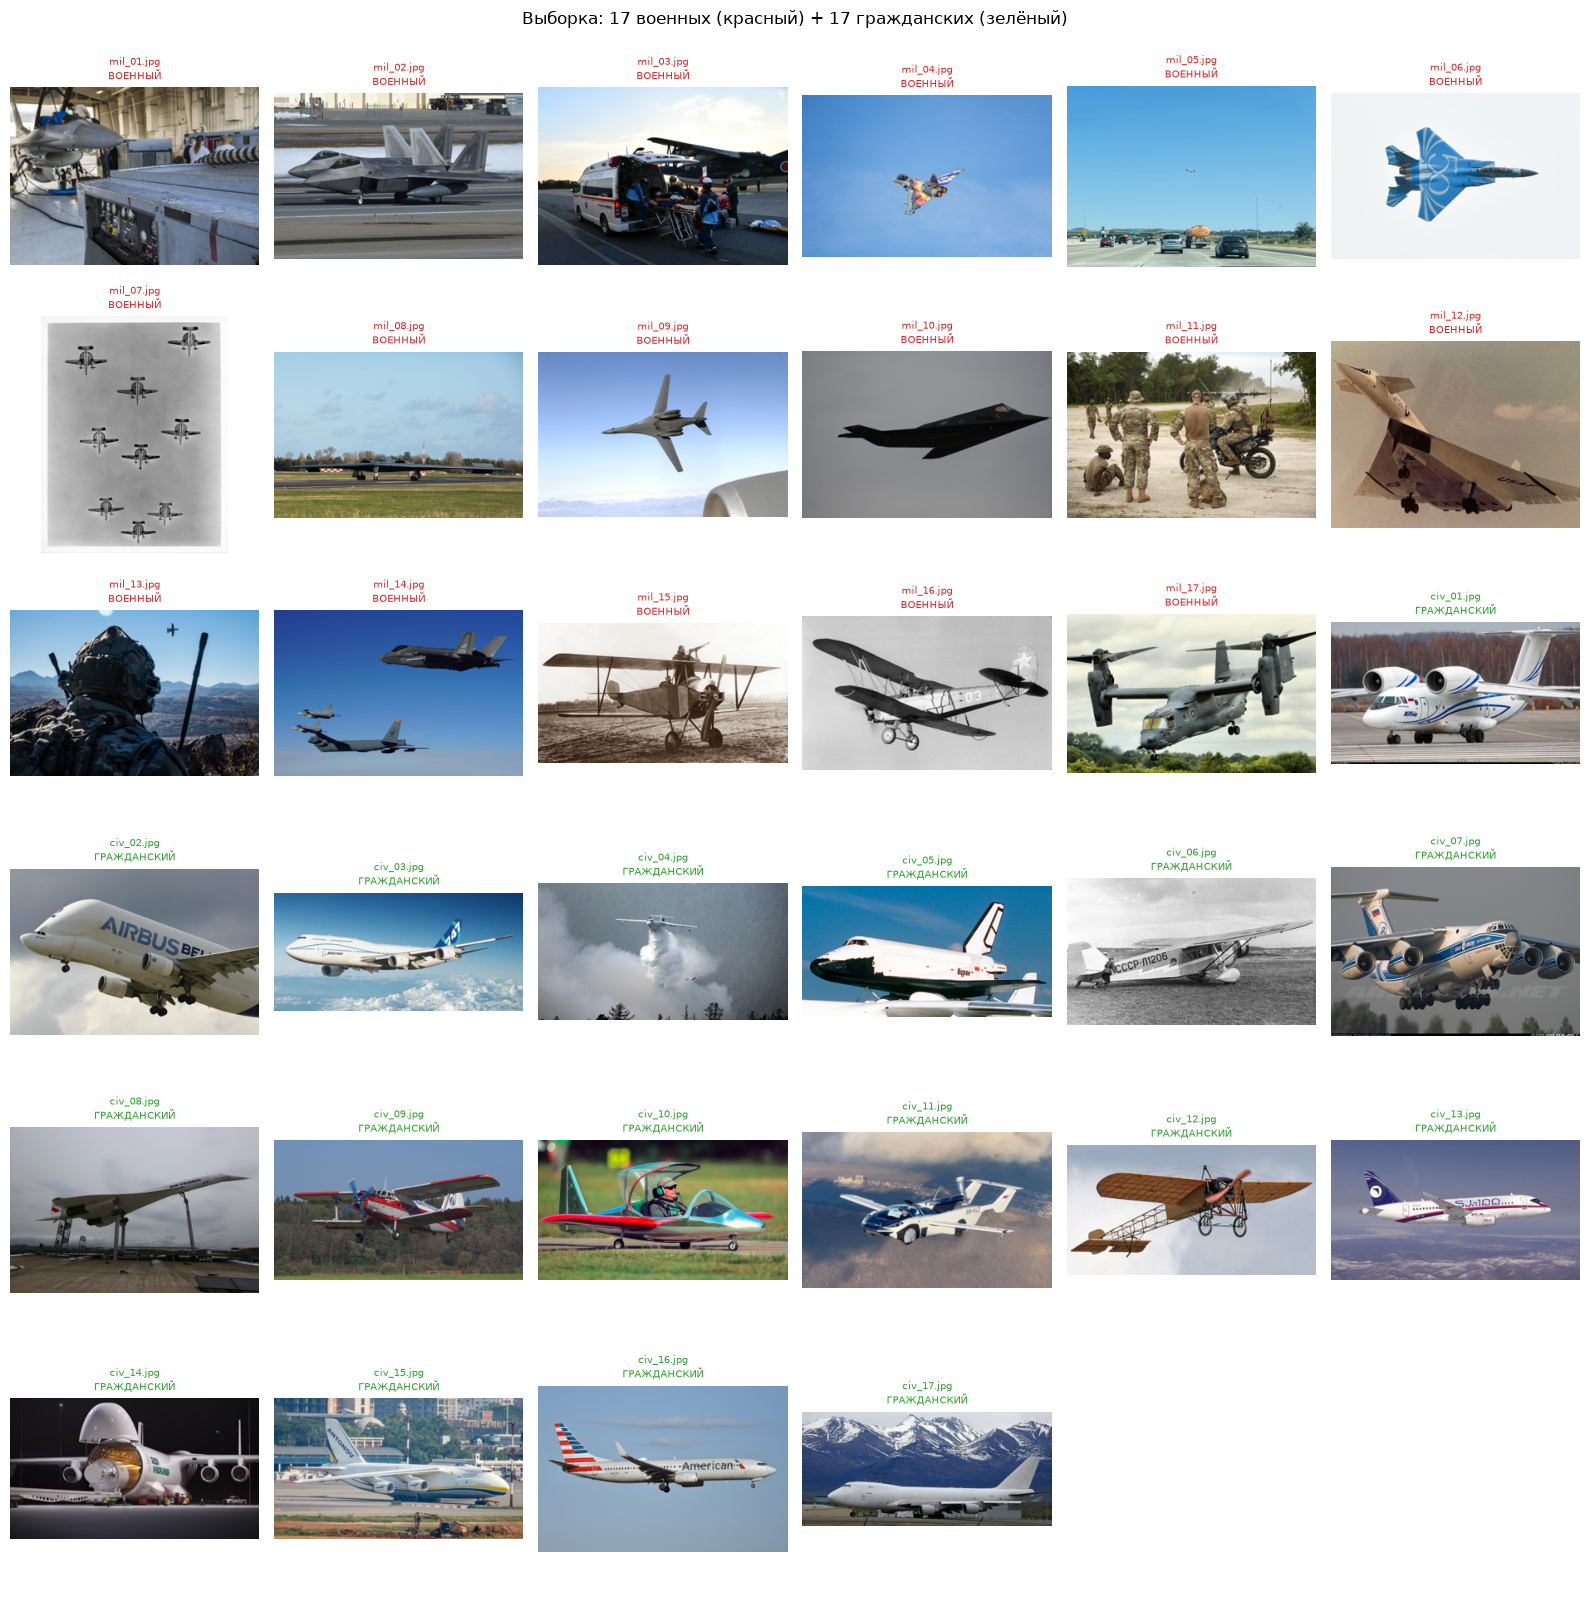

In [3]:
fig, axes = plt.subplots(6, 6, figsize=(16, 16))
for ax, r in zip(axes.ravel(), df.itertuples()):
    im = PILImage.open(os.path.join(DATASET_DIR, r.file)).convert("RGB")
    im.thumbnail((300, 300))
    ax.imshow(im)
    color = "tab:red" if r.gt == "ВОЕННЫЙ" else "tab:green"
    ax.set_title(f"{os.path.basename(r.file)}\n{r.gt}", fontsize=7, color=color)
    ax.axis("off")
for ax in axes.ravel()[len(df):]:
    ax.axis("off")
plt.suptitle("Выборка: 17 военных (красный) + 17 гражданских (зелёный)", y=0.995)
plt.tight_layout()
plt.show()

## 2. Модели, их характеристики и конфигурация

Обе модели стоят в vLLM на одной NVIDIA H100 (80 GB VRAM) и отвечают по OpenAI-совместимому API.

**Характеристики моделей:**

| | Qwen3.8-27B | Phi-3.5-Vision |
|---|---|---|
| параметры | 27B | ~4,2B |
| архитектура | «зрение» (ViT, 27 слоёв, 1152-d) + 64-слойный LLM 5120-d с гибридным вниманием (3× линейное Gated-DeltaNet + 1× полное) | «зрение» (CLIP ViT-L/14@336, 144 токена изображения) + 32-слойный LLM 3072-d |
| точность весов | bfloat16 | bfloat16 |
| весов на диске | ~52 GB | ~8 GB |

**Конфигурация сервинга (vLLM):**

| параметр | Qwen3.8-27B | Phi-3.5-Vision |
|---|---|---|
| адрес API | `http://localhost:8001/v1` | `http://localhost:8002/v1` |
| `gpu-memory-utilization` | 0.92 (~74 GB: веса + KV-кэш) | 0.5 (~40 GB) |
| `max-model-len` | 16384 | 16384 |
| `max-num-seqs` | 128 | 1024 (по умолчанию) |
| prefix caching, chunked prefill | вкл (по умолчанию vLLM v1) | вкл (по умолчанию vLLM v1) |

Вместе в 80 GB они не влезают, поэтому запускаем **последовательно**: сначала большую — дожидаемся healthcheck, прогоняем все 34 фото, останавливаем; потом маленькую.

Запуск (вне ноутбука):
```
sudo docker compose -f task3-llm/docker-compose.yml --profile strong up -d   # Qwen3.8-27B
sudo docker compose -f task3-llm/docker-compose.yml --profile strong down    # остановка
sudo docker compose -f task3-llm/docker-compose.yml --profile weak up -d     # Phi-3.5-Vision
```

**Конфигурация запроса** (одинаковая схема для обеих моделей):

| параметр | Qwen3.8-27B | Phi-3.5-Vision |
|---|---|---|
| `temperature` | 0 (воспроизводимо) | 0 |
| `max_tokens` (лимит ответа) | 1024 | 512 |

Qwen3.8 работает со встроенным «режимом размышлений»: до ответа модель пишет цепочку рассуждений — она видна в пояснениях ниже и учитывается при выборе лимита в 1024 токенов. Phi-3.5 такого режима не имеет и отвечает сразу.

**Один промпт для обеих моделей**, дословно:

> На фотографии изображён самолёт (или несколько самолётов). Определи, относится ли показанный на фото самолёт к военной или гражданской авиации.
> Ответь строго в формате: `<ответ>ВОЕННЫЙ</ответ>` или `<ответ>ГРАЖДАНСКИЙ</ответ>`
> Затем в 1-2 предложениях объясни, по каким визуальным признакам ты сделал такой вывод.

Решение модель пишет в теги `<ответ>…</ответ>`, дальше — пояснение.


In [4]:
PROMPT = (
    "На фотографии изображён самолёт (или несколько самолётов). "
    "Определи, относится ли показанный на фото самолёт к военной или гражданской авиации.\n"
    "Ответь строго в формате: <ответ>ВОЕННЫЙ</ответ> или <ответ>ГРАЖДАНСКИЙ</ответ>\n"
    "Затем в 1-2 предложениях объясни, по каким визуальным признакам ты сделал такой вывод."
)

MODELS = {
    "Qwen3.8-27B":    dict(base="http://localhost:8001/v1", name="qwen3.8-27b",
                           temperature=0, max_tokens=1024),
    "Phi-3.5-Vision": dict(base="http://localhost:8002/v1", name="phi-3.5-vision",
                           temperature=0, max_tokens=512),
}

CLASSES = ["ВОЕННЫЙ", "ГРАЖДАНСКИЙ"]
TAG_RE = re.compile(r"<ответ>\s*(ВОЕННЫЙ|ГРАЖДАНСКИЙ)\s*</ответ>", re.IGNORECASE)

print("Промпт для обеих моделей:\n")
print(PROMPT)

Промпт для обеих моделей:

На фотографии изображён самолёт (или несколько самолётов). Определи, относится ли показанный на фото самолёт к военной или гражданской авиации.
Ответь строго в формате: <ответ>ВОЕННЫЙ</ответ> или <ответ>ГРАЖДАНСКИЙ</ответ>
Затем в 1-2 предложениях объясни, по каким визуальным признакам ты сделал такой вывод.


In [5]:
def image_to_data_url(path):
    """Фото -> base64 data-URL для OpenAI API."""
    with open(path, "rb") as f:
        return "data:image/jpeg;base64," + base64.b64encode(f.read()).decode("ascii")


def ask_model(base, name, data_url, temperature=0, max_tokens=200,
              extra=None, timeout=300, retries=3):
    """Один запрос /chat/completions. Возвращает (текст, время, ошибка)."""
    payload = {
        "model": name,
        "temperature": temperature,
        "max_tokens": max_tokens,
        "messages": [{"role": "user", "content": [
            {"type": "text", "text": PROMPT},
            {"type": "image_url", "image_url": {"url": data_url}},
        ]}],
    }
    if extra:
        payload.update(extra)  # дополнительные параметры модели
    last_err, t0 = None, time.time()
    for a in range(retries):
        try:
            r = requests.post(base.rstrip("/") + "/chat/completions",
                              json=payload, timeout=timeout)
            r.raise_for_status()
            return r.json()["choices"][0]["message"]["content"], time.time() - t0, None
        except Exception as e:
            last_err = f"{type(e).__name__}: {e}"
            if a < retries - 1:
                time.sleep(2 ** (a + 1))  # паузы 2, 4, 8 c
    return None, time.time() - t0, last_err


def parse_answer(raw):
    """Достаём решение. (предсказание или None, распарсилось ли)."""
    if not raw:
        return None, False
    m = TAG_RE.search(raw)
    if m:
        return m.group(1).upper(), True
    up = raw.upper()  # запасной вариант: первое вхождение слова
    pos = sorted((up.find(c), c) for c in CLASSES if up.find(c) != -1)
    return (pos[0][1], True) if pos else (None, False)


def evaluate(model_key):
    """Прогон всех 34 фото через одну модель."""
    cfg = MODELS[model_key]
    out = []
    for i, r in enumerate(df.itertuples(), 1):
        raw, lat, err = ask_model(cfg["base"], cfg["name"],
                                  image_to_data_url(os.path.join(DATASET_DIR, r.file)),
                                  temperature=cfg["temperature"],
                                  max_tokens=cfg["max_tokens"],
                                  extra=cfg.get("extra"))
        pred, ok = parse_answer(raw)
        out.append(dict(file=r.file, gt=r.gt, difficulty=r.difficulty,
                        reason=r.reason, pred=pred, parse_ok=ok,
                        raw=raw, latency=round(lat, 2), error=err))
        print(f"[{i:2d}/34] {r.file:22s} gt={r.gt:11s} -> {str(pred):11s} "
              f"{'ok' if ok else 'НЕ РАСПАРСИЛО'} {lat:5.1f}s", flush=True)
    return out


def compute_metrics(res):
    """Метрики в лоб, без sklearn: confusion 2x2, accuracy, P/R/F1 по классам."""
    cm = {g: {p: 0 for p in CLASSES} for g in CLASSES}
    for r in res:
        if r["pred"] in cm.get(r["gt"], {}):
            cm[r["gt"]][r["pred"]] += 1
    total = len(res)
    correct = sum(cm[g][g] for g in CLASSES)
    per_class = {}
    for c in CLASSES:
        tp = cm[c][c]
        fp = sum(cm[g][c] for g in CLASSES if g != c)
        fn = sum(cm[c][p] for p in CLASSES if p != c)
        p = tp / (tp + fp) if tp + fp else 0.0
        rcl = tp / (tp + fn) if tp + fn else 0.0
        per_class[c] = dict(precision=p, recall=rcl,
                            f1=2 * p * rcl / (p + rcl) if p + rcl else 0.0,
                            support=tp + fn)
    return dict(total=total, correct=correct,
                accuracy=correct / total if total else 0.0,
                confusion=cm, per_class=per_class,
                parse_fail=[r["file"] for r in res if not r["parse_ok"]],
                mean_latency=sum(r["latency"] for r in res) / total if total else 0.0)


def show_metrics(name, res):
    """Печатает метрики модели и список её ошибок. Возвращает dict метрик."""
    m = compute_metrics(res)
    print(f"### {name}")
    print(f"accuracy = {m['accuracy']:.3f}  ({m['correct']}/{m['total']})\n")
    print("Матрица ошибок (строки — реальность, столбцы — ответ модели):")
    print("реальное     " + "".join(c.ljust(14) for c in CLASSES))
    for g in CLASSES:
        print(f"{g:13s}" + "".join(str(m['confusion'][g][p]).ljust(14) for p in CLASSES))
    print()
    for c, v in m["per_class"].items():
        print(f"{c:13s} precision={v['precision']:.3f}  recall={v['recall']:.3f}  "
              f"F1={v['f1']:.3f}  (всего {v['support']})")
    print(f"среднее время на фото: {m['mean_latency']:.2f} c")
    errs = [r for r in res if r["pred"] and r["pred"] != r["gt"]]
    print(f"\nОшибки ({len(errs)}):")
    for r in errs:
        expl = (r["raw"] or "").replace("\n", " ")
        print(f"  {r['file']}   (реальность {r['gt']}, ответ {r['pred']})")
        print(f"      {expl[:200]}")
    if m["parse_fail"]:
        print("Не распарсились ответы:", m["parse_fail"])
    return m

## 3. Qwen3.8-27B («сильная»)

Сервер запущен (профиль `strong`, порт 8001), healthcheck OK. Прогоняем все 34 фото.


In [6]:
qwen_res = evaluate("Qwen3.8-27B")

[ 1/34] military/mil_01.jpg    gt=ВОЕННЫЙ     -> ВОЕННЫЙ     ok   7.5s


[ 2/34] military/mil_02.jpg    gt=ВОЕННЫЙ     -> ВОЕННЫЙ     ok   8.7s


[ 3/34] military/mil_03.jpg    gt=ВОЕННЫЙ     -> ВОЕННЫЙ     ok   6.3s


[ 4/34] military/mil_04.jpg    gt=ВОЕННЫЙ     -> ВОЕННЫЙ     ok   9.3s


[ 5/34] military/mil_05.jpg    gt=ВОЕННЫЙ     -> ГРАЖДАНСКИЙ ok   8.7s


...

[30/34] civilian/civ_13.jpg    gt=ГРАЖДАНСКИЙ -> ГРАЖДАНСКИЙ ok   7.9s


[31/34] civilian/civ_14.jpg    gt=ГРАЖДАНСКИЙ -> ГРАЖДАНСКИЙ ok   7.1s


[32/34] civilian/civ_15.jpg    gt=ГРАЖДАНСКИЙ -> ГРАЖДАНСКИЙ ok   4.4s


[33/34] civilian/civ_16.jpg    gt=ГРАЖДАНСКИЙ -> ГРАЖДАНСКИЙ ok   4.3s


[34/34] civilian/civ_17.jpg    gt=ГРАЖДАНСКИЙ -> ГРАЖДАНСКИЙ ok   8.5s


In [7]:
qwen_m = show_metrics("Qwen3.8-27B", qwen_res)

### Qwen3.8-27B
accuracy = 0.941  (32/34)

Матрица ошибок (строки — реальность, столбцы — ответ модели):
реальное     ВОЕННЫЙ       ГРАЖДАНСКИЙ   
ВОЕННЫЙ      15            1             
ГРАЖДАНСКИЙ  0             17            

ВОЕННЫЙ       precision=1.000  recall=0.938  F1=0.968  (всего 16)
ГРАЖДАНСКИЙ   precision=0.944  recall=1.000  F1=0.971  (всего 17)
среднее время на фото: 7.81 c

Ошибки (1):
  military/mil_05.jpg   (реальность ВОЕННЫЙ, ответ ГРАЖДАНСКИЙ)
      Пользователь просит определить тип авиации на фото. На изображении в небе виден небольшой самолёт, летящий на фоне голубого неба. Нужно внимательно рассмотреть его силуэт.  Самолёт маленький, виден сн
Не распарсились ответы: ['military/mil_11.jpg']


## 4. Phi-3.5-Vision («слабая»)

Большую модель остановили, запустили маленькую (профиль `weak`, порт 8002). Тот же промпт, те же 34 фото.


In [8]:
phi_res = evaluate("Phi-3.5-Vision")

[ 1/34] military/mil_01.jpg    gt=ВОЕННЫЙ     -> ВОЕННЫЙ     ok   0.7s


[ 2/34] military/mil_02.jpg    gt=ВОЕННЫЙ     -> ВОЕННЫЙ     ok   0.8s


[ 3/34] military/mil_03.jpg    gt=ВОЕННЫЙ     -> ВОЕННЫЙ     ok   0.5s


[ 4/34] military/mil_04.jpg    gt=ВОЕННЫЙ     -> ВОЕННЫЙ     ok   0.5s


[ 5/34] military/mil_05.jpg    gt=ВОЕННЫЙ     -> ВОЕННЫЙ     ok   0.5s


...

[30/34] civilian/civ_13.jpg    gt=ГРАЖДАНСКИЙ -> ГРАЖДАНСКИЙ ok   0.8s


[31/34] civilian/civ_14.jpg    gt=ГРАЖДАНСКИЙ -> ВОЕННЫЙ     ok   0.5s


[32/34] civilian/civ_15.jpg    gt=ГРАЖДАНСКИЙ -> ГРАЖДАНСКИЙ ok   0.6s


[33/34] civilian/civ_16.jpg    gt=ГРАЖДАНСКИЙ -> ГРАЖДАНСКИЙ ok   0.6s


[34/34] civilian/civ_17.jpg    gt=ГРАЖДАНСКИЙ -> ВОЕННЫЙ     ok   0.4s


In [9]:
phi_m = show_metrics("Phi-3.5-Vision", phi_res)

### Phi-3.5-Vision
accuracy = 0.735  (25/34)

Матрица ошибок (строки — реальность, столбцы — ответ модели):
реальное     ВОЕННЫЙ       ГРАЖДАНСКИЙ   
ВОЕННЫЙ      17            0             
ГРАЖДАНСКИЙ  9             8             

ВОЕННЫЙ       precision=0.654  recall=1.000  F1=0.791  (всего 17)
ГРАЖДАНСКИЙ   precision=1.000  recall=0.471  F1=0.640  (всего 17)
среднее время на фото: 0.61 c

Ошибки (9):
  civilian/civ_01.jpg   (реальность ГРАЖДАНСКИЙ, ответ ВОЕННЫЙ)
       <ответ>ВОЕННЫЙ</вет>  На самом деле, самолёт, изображён в фотографии, является военным аппаратом, а именно ил-76ТК, который является типом военного транспортного самолета. Визуальные признаки, которы
  civilian/civ_04.jpg   (реальность ГРАЖДАНСКИЙ, ответ ВОЕННЫЙ)
       <ответ>ВОЕННЫЙ</вет>  На фотографии изображён самолёт, который выделяется тем, что он вылетает над облаками и сжигает топливо, что является характерной особенностью военных самолётов, особенно тех, к
  civilian/civ_05.jpg   (реальность ГРАЖДАНСКИЙ,

## 5. Сравнение двух моделей


In [10]:
def metrics_row(m):
    q, c = m["per_class"]["ВОЕННЫЙ"], m["per_class"]["ГРАЖДАНСКИЙ"]
    return dict(
        accuracy=m["accuracy"],
        f1_military=q["f1"], f1_civilian=c["f1"],
        precision_military=q["precision"], recall_military=q["recall"],
        precision_civilian=c["precision"], recall_civilian=c["recall"],
        mean_latency_s=m["mean_latency"],
        parse_failures=len(m["parse_fail"]),
    )


cmp_df = pd.DataFrame(
    {"Qwen3.8-27B": metrics_row(qwen_m), "Phi-3.5-Vision": metrics_row(phi_m)}
).T.round(3)
cmp_df

,accuracy,f1_military,f1_civilian,precision_military,recall_military,precision_civilian,recall_civilian,mean_latency_s,parse_failures
Qwen3.8-27B,0.941,0.968,0.971,1.000,0.938,0.944,1.000,7.807,1.0
Phi-3.5-Vision,0.735,0.791,0.640,0.654,1.000,1.000,0.471,0.606,0.0


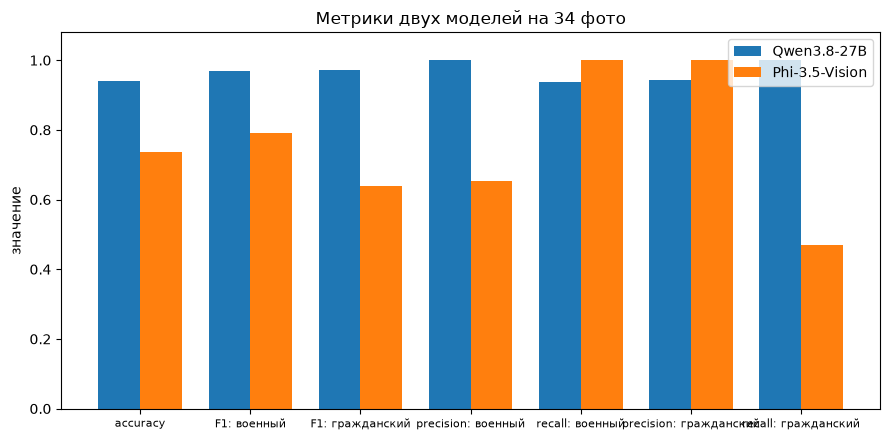

In [11]:
labels = ["accuracy", "F1: военный", "F1: гражданский",
          "precision: военный", "recall: военный",
          "precision: гражданский", "recall: гражданский"]


def vals(m):
    q, c = m["per_class"]["ВОЕННЫЙ"], m["per_class"]["ГРАЖДАНСКИЙ"]
    return [m["accuracy"], q["f1"], c["f1"],
            q["precision"], q["recall"], c["precision"], c["recall"]]


fig, ax = plt.subplots(figsize=(9, 4.5))
x = np.arange(len(labels))
w = 0.38
ax.bar(x - w / 2, vals(qwen_m), w, label="Qwen3.8-27B", color="tab:blue")
ax.bar(x + w / 2, vals(phi_m), w, label="Phi-3.5-Vision", color="tab:orange")
ax.set_xticks(x, labels, fontsize=8)
ax.set_ylim(0, 1.08)
ax.set_ylabel("значение")
ax.set_title("Метрики двух моделей на 34 фото")
ax.legend()
plt.tight_layout()
plt.show()

In [12]:
qmap = {r["file"]: r for r in qwen_res}
pmap = {r["file"]: r for r in phi_res}


def explanation(raw):
    """Текст после тега <ответ> — рассуждение модели."""
    if not raw:
        return "(нет ответа)"
    t = TAG_RE.sub("", raw).strip()
    return t[:160] if t else "(только тег, без рассуждения)"


def verdict(res, gt):
    if not res["pred"]:
        return "? нет ответа"
    return ("верно  " if res["pred"] == gt else "ошибка") + " " + res["pred"]


hard = df[df["difficulty"] == "hard"]
print(f"Нетривиальные случаи (difficulty = hard): {len(hard)}\n" + "=" * 100)
for r in hard.itertuples():
    q, p = qmap[r.file], pmap[r.file]
    print(f"\n{r.file}    реальность: {r.gt}")
    print(f"  Qwen3.8-27B: {verdict(q, r.gt)}")
    print(f"      {explanation(q['raw'])}")
    print(f"  Phi-3.5:     {verdict(p, r.gt)}")
    print(f"      {explanation(p['raw'])}")

Нетривиальные случаи (difficulty = hard): 12

military/mil_03.jpg    реальность: ВОЕННЫЙ
  Qwen3.8-27B: верно   ВОЕННЫЙ
      Пользователь просит определить тип авиации на фото и ответить строго в заданном формате, а затем дать краткое объяснение.

Анализирую изображение. На заднем пла
  Phi-3.5:     верно   ВОЕННЫЙ
      <ответ>ВОЕННЫЙ</вет>

На фотографии видно, что самолёт имеет ярко-красный цвет и имеет на его крыльце символ, который часто ассоциируется с военной авиацией. Кр

military/mil_05.jpg    реальность: ВОЕННЫЙ
  Qwen3.8-27B: ошибка ГРАЖДАНСКИЙ
      Пользователь просит определить тип авиации на фото. На изображении в небе виден небольшой самолёт, летящий на фоне голубого неба. Нужно внимательно рассмотреть 
  Phi-3.5:     верно   ВОЕННЫЙ
      Самолёт, видимый над трассой, имеет форму, которая обычно ассоциируется с военной авиацией, а не гражданской. Кроме того, его высокое расположение и отсутствие 

civilian/civ_01.jpg    реальность: ГРАЖДАНСКИЙ
  Qwen3.8-27B: верно   Г

In [13]:
out_path = os.path.join(DATASET_DIR, "predictions.csv")
one_line = lambda s: (s or "").replace("\n", " ").strip()
with open(out_path, "w", encoding="utf-8-sig", newline="") as f:
    wcsv = csv.writer(f, delimiter=";")
    wcsv.writerow(["file", "gt",
                   "qwen_pred", "qwen_parse_ok", "qwen_latency_s", "qwen_answer",
                   "phi_pred", "phi_parse_ok", "phi_latency_s", "phi_answer"])
    for r in df.itertuples():
        q, p = qmap[r.file], pmap[r.file]
        wcsv.writerow([r.file, r.gt,
                       q["pred"], q["parse_ok"], q["latency"], one_line(q["raw"]),
                       p["pred"], p["parse_ok"], p["latency"], one_line(p["raw"])])
print("Сохранено:", out_path)

Сохранено: /home/ipetrichenko/mirea-ai/notebooks/03_aircraft_llm/aircraft/predictions.csv


## 6. Выводы

| метрика | Qwen3.8-27B | Phi-3.5-Vision |
|---|---|---|
| accuracy | **0.941** (32/34) | 0.735 (25/34) |
| F1: военный | **0.968** | 0.791 |
| F1: гражданский | **0.971** | 0.640 |
| precision: военный | **1.000** | 0.654 |
| recall: военный | 0.938 | **1.000** |
| precision: гражданский | 0.944 | **1.000** |
| recall: гражданский | **1.000** | 0.471 |
| среднее время на фото | 7.81 c | **0.61 c** |
| не распарсившихся ответов | 1 | 0 |

- **Qwen3.8-27B** заметно точнее: 32 из 34 фото против 25 из 34. На гражданских самолётах он ошибается 0 раз: верно классифицирует даже «военно выглядящие» — Ан-12 в гражданской ливрее, шаттл «Буран» (читает название на борту), Конкорд, белый Boeing 747F без ливреи (по «горбу» фюзеляжа).
- Две потери Qwen — обе на «военных» фото: дальний небольшой борт без знаков (mil_05) он назвал гражданским, а на C-130 (mil_11) цепочка рассуждений оборвалась, и в лимите 1024 токенов ответа не прозвучало.
- **Phi-3.5-Vision** уверенен на «военных» (recall 1.0: 17 из 17), но из 17 гражданских верно называет только 8: на «военно выглядящие» гражданские (Ан-14, Ан-12, По-2 с бортом СССР, Конкорд, грузовой NASA, «Буран», 747F) он систематически отвечает ВОЕННЫЙ.
- Пояснения Phi-3.5 нередко галлюцинируют: у По-2 он «читает» бортовой номер «CCCP-11206» (на фото СССР-Л1206), Конкорд называет «военной ракетой», у Ан-12 ищет «надписи Военно-воздушные силы». У Qwen пояснения соответствуют тому, что видно на фото.
- Phi-3.5 отвечает в ~13 раз быстрее (0.61 с против 7.81 с на фото) и занимает вдвое меньше VRAM — это его главный плюс.
- Формат: Qwen всегда выдерживает требуемые теги; Phi-3.5 часто криво пишет закрывающий тег (`</вет>`), поэтому его решение извлекается правилом «первое вхождение слова» — парсер такие ответы ловит, parse-ошибок у него нет.
- Выборка небольшая (34 фото, из них 12 «трудных»), поэтому разницу точности правильно трактовать как оценку на этой выборке.

**Итог:** по точности и качеству рассуждений выигрывает Qwen3.8-27B (0.941 против 0.735); Phi-3.5-Vision — быстрый и компактный вариант, который на «военных» бортах не ошибается, но на «военно выглядящих» гражданских систематически склоняется к ответу ВОЕННЫЙ.
